# 04 · Models: WoE scorecard, LightGBM, CatBoost

**Goal of this notebook:** build the champion (logistic WoE scorecard) and the challengers
(LightGBM and CatBoost, each plain and with monotone constraints), and compare them on the
**test** sample. The out-of-time year 2017 stays untouched until notebook 05.

| Model | Features | Why |
|---|---|---|
| Logistic regression on WoE | 25 selected in notebook 03, reduced further here | interpretable, the bank standard |
| LightGBM / CatBoost | all 78 candidates, raw values | maximum accuracy |
| LightGBM / CatBoost, monotone | same, with business-logic directions enforced | accuracy with explainable behaviour |

**Benchmark:** Lending Club's own sub-grade. It is the output of the lender's model, built
with information the public data does not contain, so beating it is a high bar.

In [1]:
import sys
import pickle
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import lightgbm as lgb
import optuna
from catboost import CatBoostClassifier
from scipy.stats import spearmanr
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split

from src.data import TARGET
from src.features_config import model_features, CATEGORICAL, assert_no_leakage
from src.split import PROCESSED_PATH, SEED
from src.metrics import gini, ks
from src.scorecard import score_from_logit, points_table, PDO, BASE_SCORE, BASE_ODDS

FIG = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"
MODELS = ROOT / "models"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_rows", 200)
optuna.logging.set_verbosity(optuna.logging.WARNING)

def save(fig, name):
    fig.savefig(FIG / f"04_{name}.png", dpi=120, bbox_inches="tight")

C:\Users\Alex\miniconda3\envs\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

Boosting models need a holdout for early stopping and tuning. A random 10% of train is set
aside for that (**train_es**); all boosting models fit on the remaining 90%. The logistic
regression has nothing to stop early and fits on the full train.

In [2]:
samples = pd.read_parquet(PROCESSED_PATH)
train = samples[samples["sample"] == "train"].copy()
test = samples[samples["sample"] == "test"].copy()
fit_idx, es_idx = train_test_split(train.index, test_size=0.1, stratify=train[TARGET], random_state=SEED)
train_fit, train_es = train.loc[fit_idx], train.loc[es_idx]

with open(MODELS / "scorecard_binning.pkl", "rb") as fh:
    stored = pickle.load(fh)
binning, SELECTED = stored["binning"], stored["selected"]
FEATURES = model_features()
assert_no_leakage(FEATURES)
print(f"train {len(train):,} (fit {len(train_fit):,} + early stopping {len(train_es):,}) | test {len(test):,}")

train 658,463 (fit 592,616 + early stopping 65,847) | test 164,616


## 2. Champion: logistic regression on WoE

**Feature reduction rule.** Every WoE is oriented so that higher = riskier, so every
coefficient must be **positive**. Starting from the 25 features of notebook 03, the model is
refitted repeatedly, removing one feature at a time:

1. a feature with a negative coefficient (the most negative first): its effect contradicts
   its own WoE, usually because a correlated feature already carries the signal;
2. otherwise, a feature with p-value > 0.05 (the largest first).

In [3]:
W_train, W_test = binning.transform(train), binning.transform(test)
y_train, y_test = train[TARGET].to_numpy(), test[TARGET].to_numpy()

feats, log = list(SELECTED), []
while True:
    lr = sm.Logit(y_train, sm.add_constant(W_train[feats])).fit(disp=0)
    coef, pval = lr.params.drop("const"), lr.pvalues.drop("const")
    if (coef <= 0).any():
        f, reason = coef.idxmin(), f"negative coefficient ({coef.min():.3f})"
    elif (pval > 0.05).any():
        f, reason = pval.idxmax(), f"not significant (p = {pval.max():.3f})"
    else:
        break
    log.append({"feature": f, "reason": reason})
    feats.remove(f)
SCORECARD = feats
print(f"{len(SCORECARD)} features in the scorecard")
pd.DataFrame(log)

21 features in the scorecard


,feature,reason
0,open_rv_12m,negative coefficient (-0.288)
1,mort_acc,not significant (p = 0.978)
2,all_util,not significant (p = 0.712)
3,inq_last_12m,not significant (p = 0.625)


In [4]:
coef_table = pd.DataFrame({"coef": lr.params, "std_err": lr.bse, "p_value": lr.pvalues})
coef_table.round(4)

,coef,std_err,p_value
const,-3.2665,0.0074,0.0000
acc_open_past_24mths,0.5780,0.0267,0.0000
fico_range_low,0.4083,0.0269,0.0000
mths_since_rcnt_il,0.4306,0.0420,0.0000
dti,0.7532,0.0261,0.0000
mths_since_recent_inq,0.5887,0.0397,0.0000
verification_status,0.5869,0.0262,0.0000
mo_sin_rcnt_tl,0.1126,0.0360,0.0018
inq_last_6mths,0.2482,0.0368,0.0000
bc_open_to_buy,0.2333,0.0528,0.0000


In [5]:
lr_pred = {"train": lr.predict(sm.add_constant(W_train[SCORECARD])),
           "test": lr.predict(sm.add_constant(W_test[SCORECARD]))}
print(f"Scorecard Gini: train {gini(y_train, lr_pred['train']):.4f} | test {gini(y_test, lr_pred['test']):.4f}")

# Reference: the same model on every binned candidate, without the IV filter and reduction.
ALL_BINNED = [f for f in FEATURES if binning.summary().loc[f, "n_bins"] > 1]
lr_all = sm.Logit(y_train, sm.add_constant(W_train[ALL_BINNED])).fit(disp=0)
lr_all_pred = {"train": lr_all.predict(sm.add_constant(W_train[ALL_BINNED])),
               "test": lr_all.predict(sm.add_constant(W_test[ALL_BINNED]))}
print(f"Reference, {len(ALL_BINNED)} features: train {gini(y_train, lr_all_pred['train']):.4f} | "
      f"test {gini(y_test, lr_all_pred['test']):.4f}")

Scorecard Gini: train 0.3635 | test 0.3556


Reference, 70 features: train 0.3867 | test 0.3753


### 2.1 Points

The model is turned into a points table, as in a bank scorecard: **600 points = odds of
50 goods per bad, +20 points = odds doubled.** Higher score = lower risk. A loan's score
is the sum of the points of its bins.

In [6]:
points = points_table(binning, lr.params.drop("const"), lr.params["const"])
points["points"] = points["points"].round(1)
points_range = points.groupby("feature")["points"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
print("Points range by feature (max - min): how much each feature can move the score")
points_range.round(1).to_frame("range")

Points range by feature (max - min): how much each feature can move the score


,range
feature,
dti,18.6
acc_open_past_24mths,17.9
purpose,16.6
mths_since_recent_inq,15.0
fico_range_low,13.4
verification_status,11.7
mths_since_rcnt_il,11.4
percent_bc_gt_75,10.7
mo_sin_old_il_acct,9.8


In [7]:
points[points["feature"].isin(["fico_range_low", "dti", "verification_status"])]

,feature,bin,share,default_rate,woe,points
9,fico_range_low,"(-inf, 662.50)",0.100015,0.051522,0.347347,23.6
10,fico_range_low,"[662.50, 667.50)",0.094321,0.048159,0.276313,24.4
11,fico_range_low,"[667.50, 672.50)",0.093143,0.045833,0.224379,25.0
12,fico_range_low,"[672.50, 677.50)",0.080970,0.043983,0.181236,25.5
13,fico_range_low,"[677.50, 682.50)",0.078404,0.042052,0.134332,26.1
14,fico_range_low,"[682.50, 687.50)",0.067653,0.039913,0.079883,26.7
15,fico_range_low,"[687.50, 692.50)",0.064942,0.037487,0.014641,27.5
16,fico_range_low,"[692.50, 697.50)",0.058085,0.035062,-0.054751,28.3
17,fico_range_low,"[697.50, 707.50)",0.099172,0.031470,-0.166549,29.6
18,fico_range_low,"[707.50, 722.50)",0.107714,0.026521,-0.342748,31.7


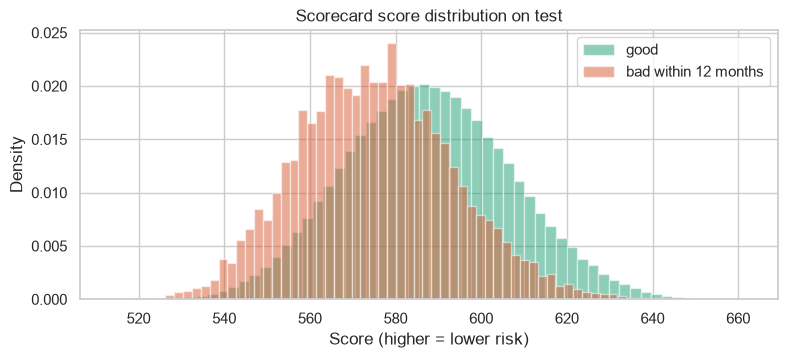

In [8]:
score_test = score_from_logit(np.log(lr_pred["test"] / (1 - lr_pred["test"])))
fig, ax = plt.subplots(figsize=(9, 3.5))
for k, color, label in [(0, "#1D9E75", "good"), (1, "#D85A30", "bad within 12 months")]:
    ax.hist(score_test[y_test == k], bins=60, density=True, alpha=0.5, color=color, label=label)
ax.set_xlabel("Score (higher = lower risk)")
ax.set_ylabel("Density")
ax.set_title("Scorecard score distribution on test")
ax.legend()
save(fig, "score_distribution")
plt.show()

## 3. Challengers: LightGBM and CatBoost

**Monotone directions.** For each numeric feature selected in notebook 03, the direction of
risk is taken from its binning (does the default rate rise or fall across bins?) and listed
below for a business-logic review. Only these features are constrained; the rest are free.

In [9]:
directions = {}
for f in SELECTED:
    if f in CATEGORICAL:
        continue
    bt = binning.table(f)
    bt = bt[~bt["Bin"].isin(["Special", "Missing", "Not reported"]) & (bt["Count"] > 0)]
    directions[f] = int(np.sign(spearmanr(range(len(bt)), bt["Event rate"])[0]))
pd.Series(directions, name="direction (+1: risk rises with the value)").to_frame()

,direction (+1: risk rises with the value)
acc_open_past_24mths,1
fico_range_low,-1
mths_since_rcnt_il,-1
dti,1
mths_since_recent_inq,-1
inq_last_12m,1
mo_sin_rcnt_tl,-1
inq_last_6mths,1
bc_open_to_buy,-1
il_util,1


In [10]:
def lgb_frame(df):
    X = df[FEATURES].copy()
    for c in CATEGORICAL:
        X[c] = pd.Categorical(X[c].astype("string"), categories=sorted(samples[c].dropna().astype(str).unique()))
    return X

def cb_frame(df):
    X = df[FEATURES].copy()
    for c in CATEGORICAL:
        X[c] = X[c].astype(str).fillna("missing")
    return X

Xl = {k: lgb_frame(d) for k, d in [("fit", train_fit), ("es", train_es), ("test", test)]}
y_fit, y_es = train_fit[TARGET].to_numpy(), train_es[TARGET].to_numpy()
MONO_LGB = [directions.get(f, 0) for f in FEATURES]

### 3.1 LightGBM: tuning with Optuna

25 trials, learning rate fixed at 0.05, early stopping on train_es. The objective is the
Gini on train_es; test is not used.

In [11]:
def lgb_model(params, monotone=False):
    p = dict(n_estimators=5000, learning_rate=0.05, subsample_freq=1, random_state=SEED,
             verbose=-1, n_jobs=12, **params)
    if monotone:
        p["monotone_constraints"] = MONO_LGB
    m = lgb.LGBMClassifier(**p)
    m.fit(Xl["fit"], y_fit, eval_X=(Xl["es"],), eval_y=(y_es,), eval_metric="auc",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m

def objective(trial):
    params = dict(
        num_leaves=trial.suggest_int("num_leaves", 15, 127, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 100, 3000, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 50, log=True),
    )
    m = lgb_model(params)
    trial.set_user_attr("trees", m.best_iteration_)
    return gini(y_es, m.predict_proba(Xl["es"])[:, 1])

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=25)
BEST = study.best_params
print("best Gini on train_es:", round(study.best_value, 4), "| trees:", study.best_trial.user_attrs["trees"])
BEST

best Gini on train_es: 0.4582 | trees: 411


{'num_leaves': 39,
 'min_child_samples': 105,
 'colsample_bytree': 0.4367209589456631,
 'subsample': 0.9339900717241408,
 'reg_lambda': 31.815462030695244}

In [12]:
models = {}
models["LightGBM"] = lgb_model(BEST)
models["LightGBM monotone"] = lgb_model(BEST, monotone=True)

### 3.2 CatBoost

Default depth (6) and regularisation, learning rate 0.1, early stopping on train_es.
CatBoost's defaults are strong and it is much slower to fit, so it is not tuned; this is a
stated limitation.

In [13]:
Xc = {k: cb_frame(d) for k, d in [("fit", train_fit), ("es", train_es), ("test", test)]}

def cb_model(monotone=False):
    m = CatBoostClassifier(iterations=3000, learning_rate=0.1, depth=6, eval_metric="AUC",
                           od_type="Iter", od_wait=100, random_seed=SEED, thread_count=12,
                           cat_features=CATEGORICAL, verbose=0,
                           monotone_constraints=directions if monotone else None)
    return m.fit(Xc["fit"], y_fit, eval_set=(Xc["es"], y_es), use_best_model=True)

models["CatBoost"] = cb_model()
models["CatBoost monotone"] = cb_model(monotone=True)

## 4. Comparison on test

In [14]:
def predict(name, part):
    X = (Xc if name.startswith("CatBoost") else Xl)[part]
    return models[name].predict_proba(X)[:, 1]

rows = []
def add(name, p_train_fit, p_test, n_features):
    rows.append({"model": name, "features": n_features,
                 "gini_train": gini(y_fit, p_train_fit), "gini_test": gini(y_test, p_test),
                 "ks_test": ks(y_test, p_test)})

idx_fit = train.index.get_indexer(fit_idx)
add("Scorecard (logistic WoE)", np.asarray(lr_pred["train"])[idx_fit], lr_pred["test"], len(SCORECARD))
add(f"Logistic WoE, all {len(ALL_BINNED)} features (reference)", np.asarray(lr_all_pred["train"])[idx_fit],
    lr_all_pred["test"], len(ALL_BINNED))
for name in models:
    add(name, predict(name, "fit"), predict(name, "test"), len(FEATURES))

sg_rank = {"fit": train_fit["sub_grade"].astype(str).rank(method="dense"),
           "test": test["sub_grade"].astype(str).rank(method="dense")}
add("Benchmark: Lending Club sub-grade", sg_rank["fit"], sg_rank["test"], 1)

comparison = pd.DataFrame(rows).set_index("model")
comparison["gini_drop"] = comparison["gini_train"] - comparison["gini_test"]
comparison.round(4)

,features,gini_train,gini_test,ks_test,gini_drop
model,,,,,
Scorecard (logistic WoE),21,0.3633,0.3556,0.2589,0.0077
"Logistic WoE, all 70 features (reference)",70,0.3856,0.3753,0.2737,0.0103
LightGBM,78,0.5858,0.4432,0.3236,0.1426
LightGBM monotone,78,0.5826,0.4430,0.3242,0.1396
CatBoost,78,0.5341,0.4382,0.3228,0.0959
CatBoost monotone,78,0.5174,0.4379,0.3246,0.0795
Benchmark: Lending Club sub-grade,1,0.4135,0.4170,0.3033,-0.0034


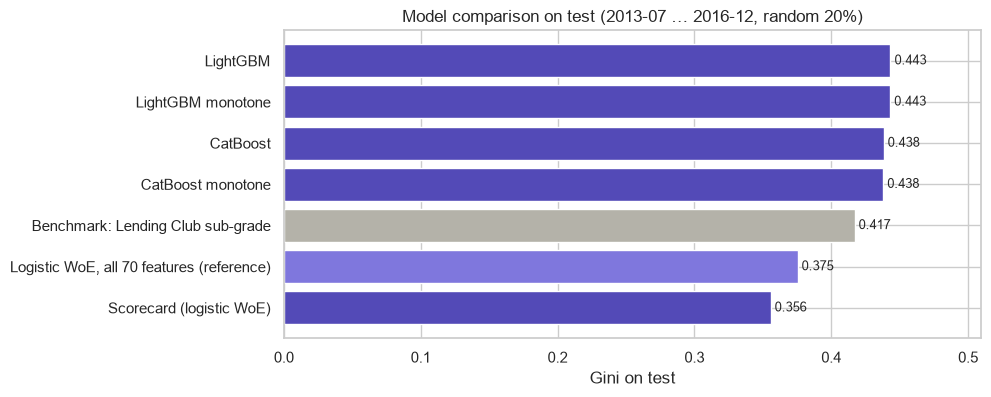

In [15]:
c = comparison.sort_values("gini_test")
colors = ["#B4B2A9" if "Benchmark" in m else "#7F77DD" if "reference" in m else "#534AB7" for m in c.index]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(c.index, c["gini_test"], color=colors)
for i, v in enumerate(c["gini_test"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, c["gini_test"].max() * 1.15)
ax.set_xlabel("Gini on test")
ax.set_title("Model comparison on test (2013-07 … 2016-12, random 20%)")
save(fig, "comparison")
plt.show()

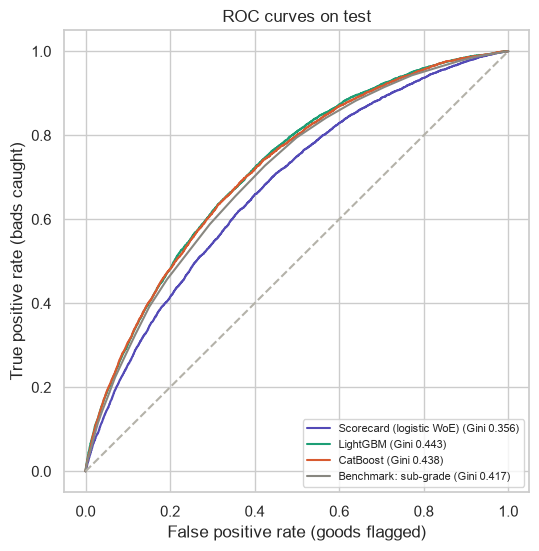

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
curves = {"Scorecard (logistic WoE)": lr_pred["test"], "LightGBM": predict("LightGBM", "test"),
          "CatBoost": predict("CatBoost", "test"), "Benchmark: sub-grade": sg_rank["test"]}
for (name, p), color in zip(curves.items(), ["#534AB7", "#1D9E75", "#D85A30", "#888780"]):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=color, label=f"{name} (Gini {gini(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#B4B2A9")
ax.set_xlabel("False positive rate (goods flagged)")
ax.set_ylabel("True positive rate (bads caught)")
ax.set_title("ROC curves on test")
ax.legend(fontsize=8, loc="lower right")
save(fig, "roc")
plt.show()

## 5. Does our model add information to the benchmark?

Beating the lender's own grade is not the only way to be useful. A bank adopting a new
score usually asks whether it **adds** information to the score already in use. Test: a
logistic regression of the target on the benchmark alone, and on the benchmark plus our
model's log-odds. The combination weights are fitted on train_es (not used to fit the
models), and Gini is measured on test.

In [17]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

# Benchmark encoded as the log-odds of its sub-grade default rate on train.
sg_rate = train.groupby(train["sub_grade"].astype(str))[TARGET].mean()
def sg_logit(df):
    return logit(df["sub_grade"].astype(str).map(sg_rate).fillna(train[TARGET].mean()))

es_pos = train.index.get_indexer(es_idx)
candidates = {
    "Scorecard (logistic WoE)": (np.asarray(lr_pred["train"])[es_pos], lr_pred["test"]),
    "LightGBM": (predict("LightGBM", "es"), predict("LightGBM", "test")),
    "CatBoost": (predict("CatBoost", "es"), predict("CatBoost", "test")),
}
base_es, base_test = sg_logit(train_es), sg_logit(test)
rows = [{"model": "Benchmark alone", "gini_test": gini(y_test, base_test)}]
for name, (p_es, p_test) in candidates.items():
    X_es = sm.add_constant(np.column_stack([base_es, logit(p_es)]))
    X_te = sm.add_constant(np.column_stack([base_test, logit(p_test)]))
    comb = sm.Logit(y_es, X_es).fit(disp=0)
    rows.append({"model": f"Benchmark + {name}", "gini_test": gini(y_test, comb.predict(X_te)),
                 "weight_benchmark": comb.params[1], "weight_model": comb.params[2],
                 "p_value_model": comb.pvalues[2]})
uplift = pd.DataFrame(rows).set_index("model")
uplift["uplift_vs_benchmark"] = uplift["gini_test"] - uplift.loc["Benchmark alone", "gini_test"]
uplift.round(4)

,gini_test,weight_benchmark,weight_model,p_value_model,uplift_vs_benchmark
model,,,,,
Benchmark alone,0.4170,NaN,NaN,NaN,0.0000
Benchmark + Scorecard (logistic WoE),0.4346,0.7938,0.4788,0.0,0.0176
Benchmark + LightGBM,0.4724,0.5442,0.7412,0.0,0.0555
Benchmark + CatBoost,0.4689,0.5701,0.7261,0.0,0.0519


## 6. Save

Models go to `models/` (not in git); the comparison and the points table go to
`reports/tables/`.

In [18]:
comparison.round(5).to_csv(TABLES / "04_model_comparison.csv")
uplift.round(5).to_csv(TABLES / "04_benchmark_uplift.csv")
points.to_csv(TABLES / "04_scorecard_points.csv", index=False)
coef_table.round(5).to_csv(TABLES / "04_scorecard_coefficients.csv")

with open(MODELS / "scorecard_logit.pkl", "wb") as fh:
    pickle.dump({"model": lr, "features": SCORECARD, "binning": binning}, fh)
for name, m in models.items():
    fname = name.lower().replace(" ", "_")
    if name.startswith("CatBoost"):
        m.save_model(str(MODELS / f"{fname}.cbm"))
    else:
        m.booster_.save_model(str(MODELS / f"{fname}.txt"))
with open(MODELS / "boosting_meta.pkl", "wb") as fh:
    pickle.dump({"features": FEATURES, "categorical": CATEGORICAL, "directions": directions,
                 "lgb_params": BEST}, fh)
print(sorted(p.name for p in MODELS.iterdir()))

['.gitkeep', 'boosting_meta.pkl', 'catboost.cbm', 'catboost_monotone.cbm', 'lightgbm.txt', 'lightgbm_monotone.txt', 'scorecard_binning.pkl', 'scorecard_logit.pkl']


## 7. Conclusions

### Results on test (2013-07 … 2016-12, random 20%)
| Model | Features | Gini test | KS test |
|---|---|---|---|
| Scorecard (logistic WoE) | 21 | 0.356 | 0.259 |
| Logistic WoE, all 70 features (reference) | 70 | 0.375 | 0.274 |
| LightGBM | 78 | **0.443** | 0.324 |
| LightGBM monotone | 78 | **0.443** | 0.324 |
| CatBoost | 78 | 0.438 | 0.323 |
| CatBoost monotone | 78 | 0.438 | 0.325 |
| Benchmark: Lending Club sub-grade | 1 | 0.417 | 0.303 |

- **The scorecard does not beat the benchmark** (0.356 vs 0.417), and neither does a logistic
  regression on all 70 binned features (0.375). Lending Club's grade was built with
  information the public data does not contain, and the grade itself set the interest rate,
  which in turn affects the payment burden. The success criterion "scorecard above the
  benchmark" is therefore expected to **fail** on OOT; this is reported, not hidden.
- **Boosting beats the benchmark** by about +0.026 Gini and the scorecard by +0.087. The gap
  between scorecard and boosting is large enough to be a real trade-off between accuracy and
  interpretability, not noise.
- **Monotone constraints cost nothing:** LightGBM 0.4430 vs 0.4432, CatBoost 0.4379 vs 0.4382.
  The monotone versions are preferred: same accuracy, behaviour that can be explained
  (for example, risk never decreases as DTI rises).
- The IV filter and the coefficient-sign reduction cost the scorecard about 0.02 Gini
  (0.356 vs 0.375 for all features): the price of a short, explainable card.

### Every model adds information to the benchmark
Adding our model's log-odds to the benchmark improves test Gini in every case
(p < 0.001): scorecard +0.018, CatBoost +0.052, **LightGBM +0.056** (0.417 → 0.472). So even
the scorecard, which is weaker than the grade alone, carries information the grade does not.
In practice, a lender would use such a model **alongside** its existing score.

### Scorecard
- 4 of the 25 features from notebook 03 were removed: `open_rv_12m` (negative coefficient,
  its signal is already in `acc_open_past_24mths`), `mort_acc`, `all_util`, `inq_last_12m`
  (not significant). All 21 remaining coefficients are positive with p < 0.01.
- Points: 600 = odds 50:1, +20 = odds doubled. The features that move the score most are
  DTI (18.6 points between best and worst bin), accounts opened in 24 months (17.9),
  purpose (16.6) and months since the last inquiry (15.0); FICO moves it by 13.4.
- Train/test Gini differ by 0.008: no overfitting.

### Findings for Part 2 (validation)
- **Boosting overfits its training data strongly:** in-sample Gini 0.53–0.59 against 0.44 on
  test. Its honest development estimate is the early-stopping holdout (LightGBM 0.458, slightly
  optimistic because it was also used for tuning) and test (0.443). The "Gini drop ≤ 5 pp"
  criterion must be measured on test → OOT, not on in-sample train.
- Only LightGBM was tuned (25 Optuna trials); CatBoost uses defaults. CatBoost might gain from
  tuning, so the LightGBM vs CatBoost ranking is not final.
- Boosting uses the 2016 bureau fields raw, so for loans issued before 2016 "missing" still
  partly means "older loan" (finding from notebook 02). This must be checked on OOT, where
  every loan has these fields.
- Monotone directions were derived from the data (binning trends) and reviewed: all agree with
  business logic (risk rises with DTI, inquiries, utilisation and new accounts; falls with FICO,
  income, credit limits and age of accounts).